# Data cleaning and analysis


In [1]:
# Importing all the modules needed

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random

#Choosing a seed for reproducibility
random.seed(42)

### Exploring the data

In [2]:
# Importing the data and viewing the first 20 rows of the data

cafe_data = pd.read_csv("dirty_cafe_sales.csv")

print(cafe_data.head(20))

   Transaction ID      Item Quantity Price Per Unit Total Spent  \
0     TXN_1961373    Coffee        2            2.0         4.0   
1     TXN_4977031      Cake        4            3.0        12.0   
2     TXN_4271903    Cookie        4            1.0       ERROR   
3     TXN_7034554     Salad        2            5.0        10.0   
4     TXN_3160411    Coffee        2            2.0         4.0   
5     TXN_2602893  Smoothie        5            4.0        20.0   
6     TXN_4433211   UNKNOWN        3            3.0         9.0   
7     TXN_6699534  Sandwich        4            4.0        16.0   
8     TXN_4717867       NaN        5            3.0        15.0   
9     TXN_2064365  Sandwich        5            4.0        20.0   
10    TXN_2548360     Salad        5            5.0        25.0   
11    TXN_3051279  Sandwich        2            4.0         8.0   
12    TXN_7619095  Sandwich        2            4.0         8.0   
13    TXN_9437049    Cookie        5            1.0         5.

In [3]:
# printing the data types

print(cafe_data.dtypes)

Transaction ID      str
Item                str
Quantity            str
Price Per Unit      str
Total Spent         str
Payment Method      str
Location            str
Transaction Date    str
dtype: object


In [4]:
# printing all the the unique values except in transaction id and transaction date columns

for column in cafe_data.columns:
    if column == "Transaction ID" or column == "Transaction Date":
        continue
    print(column)
    print(cafe_data[column].unique())
    print("")

Item
<StringArray>
[  'Coffee',     'Cake',   'Cookie',    'Salad', 'Smoothie',  'UNKNOWN',
 'Sandwich',        nan,    'ERROR',    'Juice',      'Tea']
Length: 11, dtype: str

Quantity
<StringArray>
['2', '4', '5', '3', '1', 'ERROR', 'UNKNOWN', nan]
Length: 8, dtype: str

Price Per Unit
<StringArray>
['2.0', '3.0', '1.0', '5.0', '4.0', '1.5', nan, 'ERROR', 'UNKNOWN']
Length: 9, dtype: str

Total Spent
<StringArray>
[    '4.0',    '12.0',   'ERROR',    '10.0',    '20.0',     '9.0',    '16.0',
    '15.0',    '25.0',     '8.0',     '5.0',     '3.0',     '6.0',       nan,
 'UNKNOWN',     '2.0',     '1.0',     '7.5',     '4.5',     '1.5']
Length: 20, dtype: str

Payment Method
<StringArray>
['Credit Card', 'Cash', 'UNKNOWN', 'Digital Wallet', 'ERROR', nan]
Length: 6, dtype: str

Location
<StringArray>
['Takeaway', 'In-store', 'UNKNOWN', nan, 'ERROR']
Length: 5, dtype: str



In [5]:
# printing the amount of times each unique value appears in each column except the transaction id and transaction date columns

value_counts_dict = {}

for column in cafe_data.columns:
    if column == "Transaction ID" or column == "Transaction Date":
        continue
    print(cafe_data[column].value_counts())
    print("")

Item
Juice       1171
Coffee      1165
Salad       1148
Cake        1139
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
UNKNOWN      344
ERROR        292
Name: count, dtype: int64

Quantity
5          2013
2          1974
4          1863
3          1849
1          1822
UNKNOWN     171
ERROR       170
Name: count, dtype: int64

Price Per Unit
3.0        2429
4.0        2331
2.0        1227
5.0        1204
1.0        1143
1.5        1133
ERROR       190
UNKNOWN     164
Name: count, dtype: int64

Total Spent
6.0        979
12.0       939
3.0        930
4.0        923
20.0       746
15.0       734
8.0        677
10.0       524
2.0        497
9.0        479
5.0        468
16.0       444
25.0       259
7.5        237
1.0        232
4.5        225
1.5        205
UNKNOWN    165
ERROR      164
Name: count, dtype: int64

Payment Method
Digital Wallet    2291
Credit Card       2273
Cash              2258
ERROR              306
UNKNOWN            293
Name: count, dtype: int64


### Cleaning the Data

In [6]:
# replacing 'UNKNOWN' and 'ERROR' with NA values

cafe_data = cafe_data.replace(["UNKNOWN" , "ERROR"] , np.nan)

In [7]:
# changing the data types to the most suitable one for each column

cafe_data = cafe_data.astype({'Quantity' : 'float64' ,
                               'Price Per Unit' : 'float64' ,
                                 'Total Spent' : 'float64' ,
                                 })

cafe_data['Transaction Date'] = pd.to_datetime(cafe_data['Transaction Date'] , format=r"%Y-%m-%d")

print(cafe_data.dtypes)

Transaction ID                 str
Item                           str
Quantity                   float64
Price Per Unit             float64
Total Spent                float64
Payment Method                 str
Location                       str
Transaction Date    datetime64[us]
dtype: object


In [8]:
# calculating what percentage of the 'Item' column is NA

print((cafe_data["Item"].isna().sum() / len(cafe_data)) * 100)

9.69


In [9]:
# Finding what the item is based of the price per unit

cost_to_item = {
    1.0: ["Cookie"],
    1.5: ["Tea"],
    2.0: ["Coffee"],
    3.0: ["Juice", "Cake"],
    4.0: ["Sandwich", "Smoothie"],
    5.0: ["Salad"]}

for i in cafe_data.index[cafe_data['Item'].isna()]:
    if cafe_data.isna().loc[i , "Price Per Unit"]:

        # if the price per unit value is also NA at that index, we find the price per unit by dividing the total spent by the quantity, then we can find out which item it is
        # If the either the quantity or the total spent value is also NA then we simply drop the row because we are not able to figure out the data only using one of these columns

        # Using random.choice here to impute since juice and cake appear rougly the same amount of times, giving them an equal probability of being picked. Same goes for sandwiches and smoothies

        if cafe_data.isna().loc[i , "Quantity"] or cafe_data.isna().loc[i , "Total Spent"]:
            cafe_data = cafe_data.drop(index=i)
        else:
            cafe_data.loc[i , "Price Per Unit"] = (cafe_data["Total Spent"][i]) / (cafe_data["Quantity"][i])
            cafe_data.loc[i , "Item"] = random.choice(cost_to_item.get(cafe_data.loc[i , "Price Per Unit"]))
    else:
        cafe_data.loc[i , "Item"] = random.choice(cost_to_item.get(cafe_data.loc[i , "Price Per Unit"]))

#Check if all NA values have been successfully replaced/removed:
print(cafe_data['Item'].isna().sum())

0


In [10]:
# calculating what percentage of the 'Price Per Unit' column is NA

print((cafe_data["Price Per Unit"].isna().sum() / len(cafe_data)) * 100)

4.792875725435261


In [11]:
# Finding the price per unit based on what item it is

item_to_cost = {"Cookie" : 1.0, 
                "Tea" : 1.5,
                "Coffee" : 2.0,
                "Juice" : 3.0,
                "Cake" : 3.0,
                "Sandwich" : 4.0,
                "Smoothie" : 4.0,
                "Salad" : 5.0}

for i in cafe_data.index[cafe_data['Price Per Unit'].isna()]:
    cafe_data.loc[i , "Price Per Unit"] = item_to_cost.get(cafe_data.loc[i , "Item"])

#Check if all NA values have been successfully replaced:
print(cafe_data['Price Per Unit'].isna().sum())
    

0


In [12]:
# calculating what percentage of the 'Quantity' column is NA

print((cafe_data["Quantity"].isna().sum() / len(cafe_data)) * 100)

4.762857714628777


In [13]:
# Printing how many times each item was sold for every possible amount of quantity

for item in cafe_data["Item"].unique():
    print(f"{item}:")
    print(cafe_data[cafe_data["Item"] == item]["Quantity"].value_counts())
    print()


Coffee:
Quantity
5.0    269
3.0    243
1.0    241
2.0    235
4.0    230
Name: count, dtype: int64

Cake:
Quantity
5.0    273
2.0    259
4.0    231
1.0    231
3.0    228
Name: count, dtype: int64

Cookie:
Quantity
2.0    256
4.0    244
1.0    232
5.0    223
3.0    201
Name: count, dtype: int64

Salad:
Quantity
5.0    256
2.0    251
1.0    248
4.0    241
3.0    218
Name: count, dtype: int64

Smoothie:
Quantity
5.0    251
2.0    235
4.0    233
3.0    228
1.0    209
Name: count, dtype: int64

Juice:
Quantity
3.0    259
2.0    253
5.0    244
4.0    244
1.0    235
Name: count, dtype: int64

Sandwich:
Quantity
5.0    258
3.0    246
1.0    232
2.0    221
4.0    219
Name: count, dtype: int64

Tea:
Quantity
2.0    263
5.0    239
3.0    226
4.0    219
1.0    194
Name: count, dtype: int64



In [14]:
# Finding the quantity

# If the value in 'Total Spent' column is missing then I simply leave the value for the Quantity as NA since we dont have enough information to calculate it

for i in cafe_data.index[cafe_data['Quantity'].isna()]:

    if cafe_data.isna().loc[i , "Total Spent"] == False:

        # Finding the quantity by dividing the total spent by the price per unit

        cafe_data.loc[i , "Quantity"] = (cafe_data["Total Spent"][i] / cafe_data["Price Per Unit"][i])

# Calculating new percentage of NA values in this column
print((cafe_data["Quantity"].isna().sum() / len(cafe_data)) * 100)

0.20012007204322593


In [15]:
# calculating what percentage of the 'Total Spent' column is NA

print((cafe_data["Total Spent"].isna().sum() / len(cafe_data)) * 100)

4.992995797478486


In [42]:
# Finding the Total spent by multiplying the quantity by the price per unit

# Some entries in the 'Quantity' column will be missing aswell, in that case 'Total Spent' will also remain as NA

for i in cafe_data.index[cafe_data['Total Spent'].isna()]:
    cafe_data.loc[i , "Total Spent"] = (cafe_data["Quantity"][i] * cafe_data["Price Per Unit"][i])

#Calculating new percentage of NA values in this column
print((cafe_data["Total Spent"].isna().sum() / len(cafe_data)) * 100)

0.20977554017201594


In [17]:
# Finding out how many missing dates there are

null_dates = cafe_data['Transaction Date'].isna().value_counts()
print(null_dates)

Transaction Date
False    9534
True      460
Name: count, dtype: int64


In [18]:
# calculating what percentage of the Transaction date column is NA

print((cafe_data["Transaction Date"].isna().sum() / len(cafe_data)) * 100)

4.602761656994196


In [19]:
# Dropping any columns with a missing date 

cafe_data = cafe_data.dropna(subset='Transaction Date').reset_index(drop=True)

In [20]:
# sorting data by the transaction date in ascending order

cafe_data = cafe_data.sort_values(by='Transaction Date' , ascending=True).reset_index(drop=True)
print(cafe_data.head(50))

   Transaction ID      Item  Quantity  Price Per Unit  Total Spent  \
0     TXN_8249251      Cake       3.0             3.0          9.0   
1     TXN_3093284    Coffee       4.0             2.0          8.0   
2     TXN_5728991     Salad       2.0             5.0         10.0   
3     TXN_7367474     Juice       5.0             3.0         15.0   
4     TXN_2104473      Cake       3.0             3.0          9.0   
5     TXN_6093955       Tea       5.0             1.5          7.5   
6     TXN_1604072    Coffee       2.0             2.0          4.0   
7     TXN_2192787  Sandwich       5.0             4.0         20.0   
8     TXN_1581562    Coffee       2.0             2.0          4.0   
9     TXN_2024598  Sandwich       1.0             4.0          4.0   
10    TXN_8842223  Sandwich       5.0             4.0         20.0   
11    TXN_2690222      Cake       4.0             3.0         12.0   
12    TXN_4292280      Cake       4.0             3.0         12.0   
13    TXN_4801947   

In [21]:
# Setting the index to the transaction date column

cafe_data = cafe_data.set_index('Transaction Date')

print(cafe_data)

                 Transaction ID      Item  Quantity  Price Per Unit  \
Transaction Date                                                      
2023-01-01          TXN_8249251      Cake       3.0             3.0   
2023-01-01          TXN_3093284    Coffee       4.0             2.0   
2023-01-01          TXN_5728991     Salad       2.0             5.0   
2023-01-01          TXN_7367474     Juice       5.0             3.0   
2023-01-01          TXN_2104473      Cake       3.0             3.0   
...                         ...       ...       ...             ...   
2023-12-31          TXN_8933459     Juice       1.0             3.0   
2023-12-31          TXN_1714348  Sandwich       2.0             4.0   
2023-12-31          TXN_7108012       Tea       1.0             1.5   
2023-12-31          TXN_2975443     Salad       5.0             5.0   
2023-12-31          TXN_7326974      Cake       4.0             3.0   

                  Total Spent  Payment Method  Location  
Transaction Date  

### Plotting graphs

In [22]:
# making a series with the weekly sales of the cafe

cafe_weekly_sales = cafe_data['Total Spent'].resample('W').sum()

In [23]:
# Viewing the first 5 rows of this series

print(cafe_weekly_sales.head())

Transaction Date
2023-01-01     176.0
2023-01-08    1717.5
2023-01-15    1731.5
2023-01-22    1455.0
2023-01-29    1621.5
Freq: W-SUN, Name: Total Spent, dtype: float64


In [24]:
# dropping the first row since it only takes into account 1 day

cafe_weekly_sales = cafe_weekly_sales.drop('2023-01-01')

In [25]:
# confirming

print(cafe_weekly_sales.head())

Transaction Date
2023-01-08    1717.5
2023-01-15    1731.5
2023-01-22    1455.0
2023-01-29    1621.5
2023-02-05    1644.0
Freq: W-SUN, Name: Total Spent, dtype: float64


In [26]:
# Finding the average weekly sales

average_weekly_sales = round(cafe_weekly_sales.values.mean(), 2)

#Checking
print(average_weekly_sales)

1628.7


In [27]:
#finding the 4-week rolling average 

four_week_average = cafe_weekly_sales.rolling(window=4).mean()

#checking
print(four_week_average)

Transaction Date
2023-01-08         NaN
2023-01-15         NaN
2023-01-22         NaN
2023-01-29    1631.375
2023-02-05    1613.000
2023-02-12    1599.875
2023-02-19    1654.625
2023-02-26    1665.000
2023-03-05    1639.375
2023-03-12    1599.625
2023-03-19    1650.500
2023-03-26    1644.625
2023-04-02    1694.125
2023-04-09    1716.375
2023-04-16    1661.875
2023-04-23    1693.750
2023-04-30    1653.375
2023-05-07    1653.500
2023-05-14    1608.500
2023-05-21    1594.125
2023-05-28    1578.000
2023-06-04    1545.125
2023-06-11    1593.500
2023-06-18    1628.500
2023-06-25    1660.750
2023-07-02    1727.375
2023-07-09    1701.375
2023-07-16    1621.750
2023-07-23    1618.000
2023-07-30    1562.875
2023-08-06    1571.500
2023-08-13    1586.250
2023-08-20    1592.625
2023-08-27    1604.750
2023-09-03    1576.625
2023-09-10    1643.000
2023-09-17    1603.875
2023-09-24    1602.375
2023-10-01    1621.250
2023-10-08    1582.125
2023-10-15    1574.750
2023-10-22    1632.750
2023-10-29    164

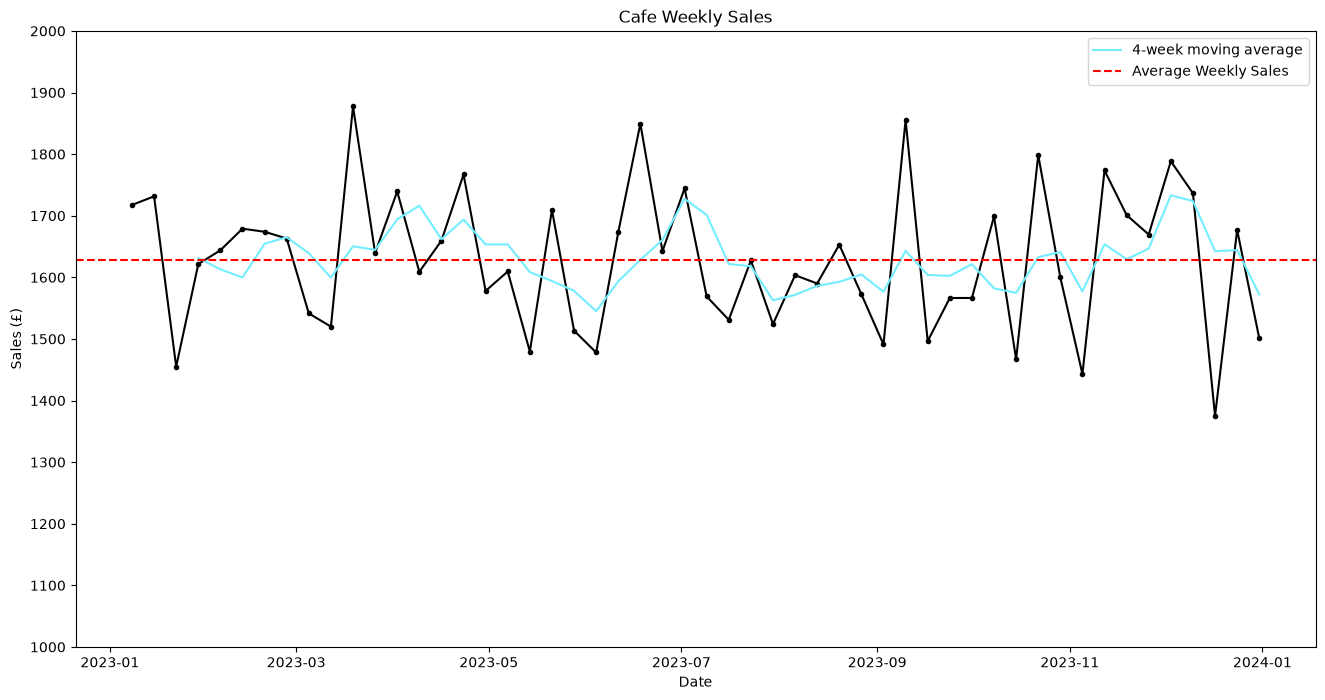

In [28]:
# graphing the cafe's weekly sales

plt.figure(figsize=(16,8))

plt.plot(cafe_weekly_sales , color='black' , marker='.')

#Adding a 4-week moving average:
plt.plot(four_week_average,color='#73EEFF', label='4-week moving average')

#Setting labels
plt.title('Cafe Weekly Sales')
plt.xlabel('Date')
plt.ylabel('Sales (£)')
plt.yticks(np.linspace(1000,2000, num=11))

#Adding a horizontal line showing the average
plt.axhline(average_weekly_sales,
            linestyle="--",
            label='Average Weekly Sales',
            color='red')


plt.legend()
plt.show()

In [29]:
# making a series with the monthly sales of the cafe

cafe_monthly_sales = cafe_data['Total Spent'].resample('ME').sum()

In [30]:
# viewing this series

print(cafe_monthly_sales)

Transaction Date
2023-01-31    7254.0
2023-02-28    6644.0
2023-03-31    7216.0
2023-04-30    7179.0
2023-05-31    6932.5
2023-06-30    7353.0
2023-07-31    6877.5
2023-08-31    7092.5
2023-09-30    6871.0
2023-10-31    7314.0
2023-11-30    6967.0
2023-12-31    7168.0
Freq: ME, Name: Total Spent, dtype: float64


In [31]:
#Finding the average monthly sales

average_monthly_sales = cafe_monthly_sales.values.mean()

#Checking:
print(average_monthly_sales)

7072.375


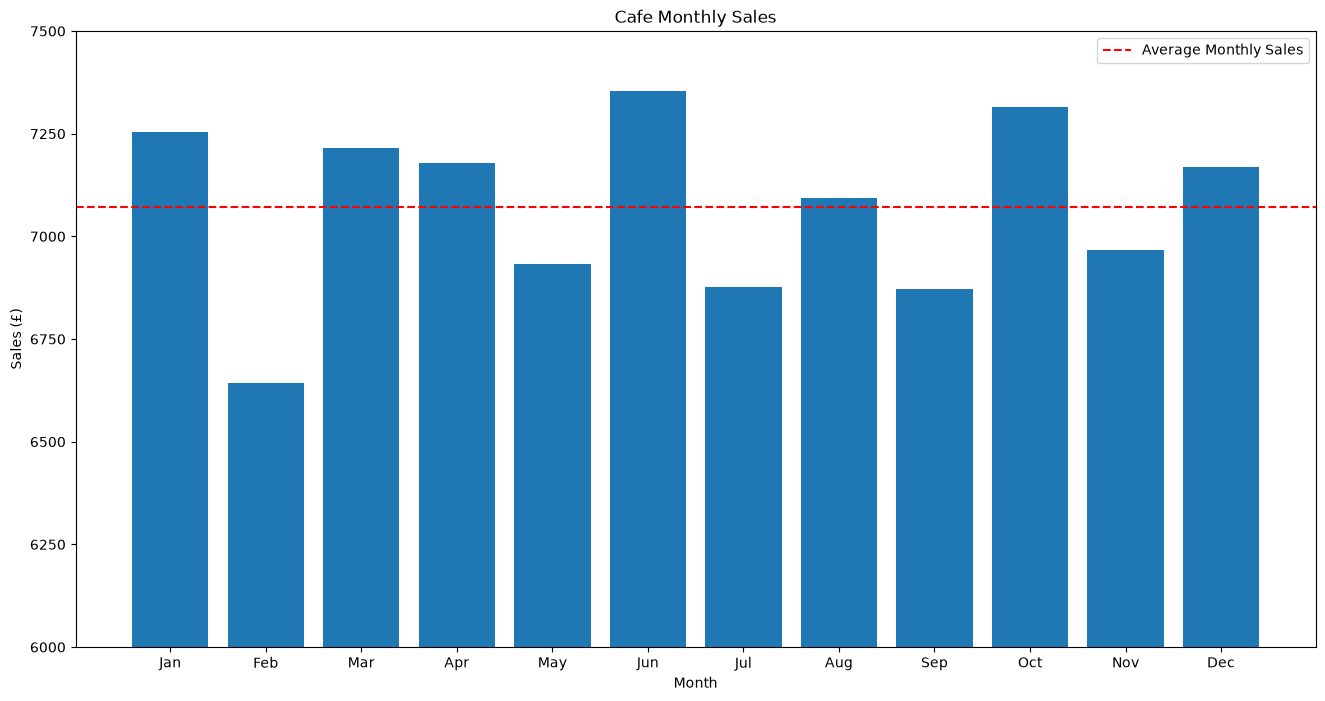

In [32]:
# Graphing the cafe's monthly sales

plt.figure(figsize=(16,8))

plt.bar(cafe_monthly_sales.index.strftime('%b'), cafe_monthly_sales.values)
plt.title("Cafe Monthly Sales")
plt.xlabel("Month")
plt.ylabel("Sales (£)")

#Having y-axis be between 6000 and 7500 to clearly show differences in monthly sales
plt.ylim(6000,7500)
plt.yticks(np.arange(6000,7501,250))

#Adding a horizontal line showing the average monthly sales:
plt.axhline(average_monthly_sales,
            linestyle="--",
            label="Average Monthly Sales",
            color='red')

plt.legend()
plt.show()

In [33]:
# Creating series with total sales for each day of the week:

total_daily_sales = cafe_data.groupby(cafe_data.index.day_name())['Total Spent'].sum()

# Viewing the series:

print(total_daily_sales)



Transaction Date
Friday       12334.0
Monday       12140.0
Saturday     11994.5
Sunday       12287.5
Thursday     12401.5
Tuesday      12039.5
Wednesday    11671.5
Name: Total Spent, dtype: float64


In [34]:
# finding how many times each day of the week appears in total in the data set

#Series with total sales per day
daily_sales = cafe_data['Total Spent'].resample('D').sum()

#looping through the days in daily_sales to count how many of each day of the week there is in total in the dataset
days_count = {"Sunday":0 ,
            "Monday":0 ,
            "Tuesday":0 ,
            "Wednesday":0 ,
            "Thursday":0 ,
            "Friday":0 ,
            "Saturday":0}

for day in daily_sales.index.day_name():
    days_count[day] += 1

#Checking
print(days_count)

{'Sunday': 53, 'Monday': 52, 'Tuesday': 52, 'Wednesday': 52, 'Thursday': 52, 'Friday': 52, 'Saturday': 52}


In [35]:
# Creating a series with average total sales for each day of the week

average_daily_sales = total_daily_sales.copy()

#Created a copy of the total daily sales and looping through it and dividing every value by how many of those days there in the year to get the average daily sales for each day of the week

for day,count in days_count.items():
    average_daily_sales.loc[day] = round((average_daily_sales[day] / count), 2)

#Checking
print(average_daily_sales)
    

Transaction Date
Friday       237.19
Monday       233.46
Saturday     230.66
Sunday       231.84
Thursday     238.49
Tuesday      231.53
Wednesday    224.45
Name: Total Spent, dtype: float64


In [36]:
# Arranging the days in chronological order:

days_order = ["Monday", "Tuesday", "Wednesday", "Thursday",
              "Friday", "Saturday", "Sunday"]

total_daily_sales = total_daily_sales.reindex(days_order)
average_daily_sales = average_daily_sales.reindex(days_order)

#Checking:

print(total_daily_sales)
print()
print(average_daily_sales)

Transaction Date
Monday       12140.0
Tuesday      12039.5
Wednesday    11671.5
Thursday     12401.5
Friday       12334.0
Saturday     11994.5
Sunday       12287.5
Name: Total Spent, dtype: float64

Transaction Date
Monday       233.46
Tuesday      231.53
Wednesday    224.45
Thursday     238.49
Friday       237.19
Saturday     230.66
Sunday       231.84
Name: Total Spent, dtype: float64


<Figure size 1600x800 with 0 Axes>

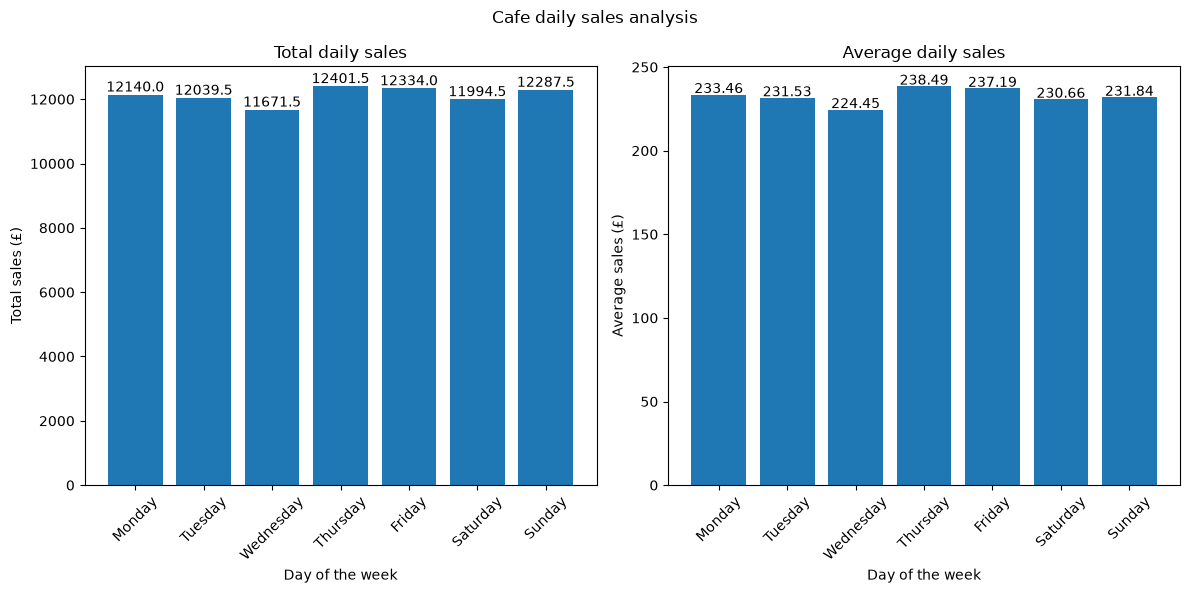

In [37]:
# Graphing total daily sales and average daily sales next to eachother

plt.figure(figsize=(16,8))

fig, ax = plt.subplots(1, 2, figsize=(12,6))

fig.suptitle("Cafe daily sales analysis")

#Bar chart of the total daily sales
ax[0].bar(total_daily_sales.index , total_daily_sales.values)
ax[0].set_title("Total daily sales")
ax[0].set_xlabel("Day of the week")
ax[0].set_ylabel("Total sales (£)")
ax[0].tick_params(axis='x', rotation=45)

#adding value lables above each bar
for day,amount in enumerate(total_daily_sales):
    ax[0].text(day, amount+100 , amount, ha='center')

#Bar chart of the average daily sales
ax[1].bar(average_daily_sales.index , average_daily_sales.values)
ax[1].set_title("Average daily sales")
ax[1].set_xlabel("Day of the week")
ax[1].set_ylabel("Average sales (£)")
ax[1].tick_params(axis='x', rotation=45)

#adding value lables above each bar
for day,amount in enumerate(average_daily_sales):
    ax[1].text(day, amount+1 , amount, ha='center')

plt.tight_layout()
plt.show()


In [38]:
# creating a series with the total quantity sold of each item for the year

total_sales_per_item = cafe_data.groupby('Item')['Quantity'].sum()
print(total_sales_per_item)

Item
Cake        3665.0
Coffee      3766.0
Cookie      3427.0
Juice       3671.0
Salad       3644.0
Sandwich    3606.0
Smoothie    3524.0
Tea         3441.0
Name: Quantity, dtype: float64


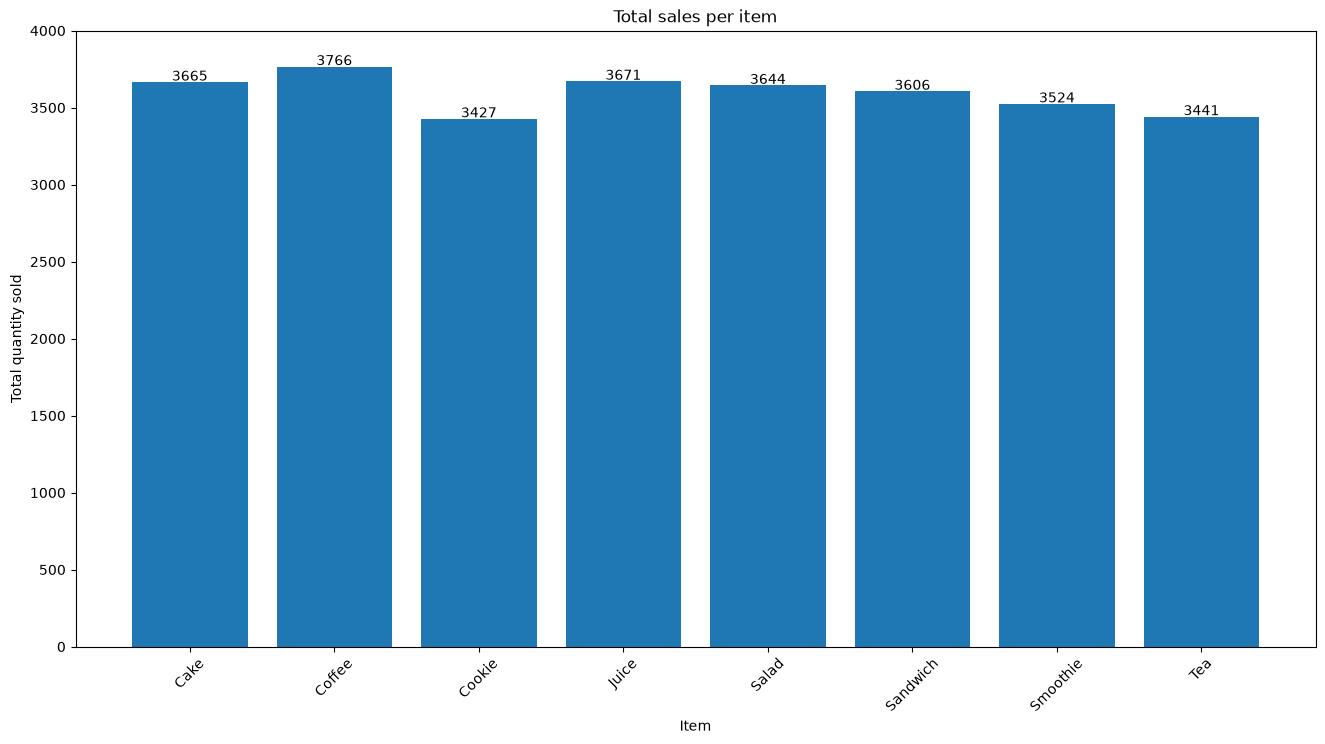

In [39]:
# graphing this data using a bar chart

plt.figure(figsize=(16,8))

plt.bar(total_sales_per_item.index , total_sales_per_item.values)
plt.title("Total sales per item")
plt.xlabel("Item")
plt.ylabel("Total quantity sold")
plt.ylim(0,4000)

#adding value lables above each bar
for item,amount in enumerate(total_sales_per_item):
    plt.text(item, amount+10, int(amount), ha='center')

plt.xticks(rotation=45)
plt.show()

In [40]:
#Creating a series with the total revenue per product

total_revenue_per_item = cafe_data.groupby('Item')['Total Spent'].sum()

#Checking:
print(total_revenue_per_item)

Item
Cake        10995.0
Coffee       7532.0
Cookie       3427.0
Juice       11013.0
Salad       18220.0
Sandwich    14424.0
Smoothie    14096.0
Tea          5161.5
Name: Total Spent, dtype: float64


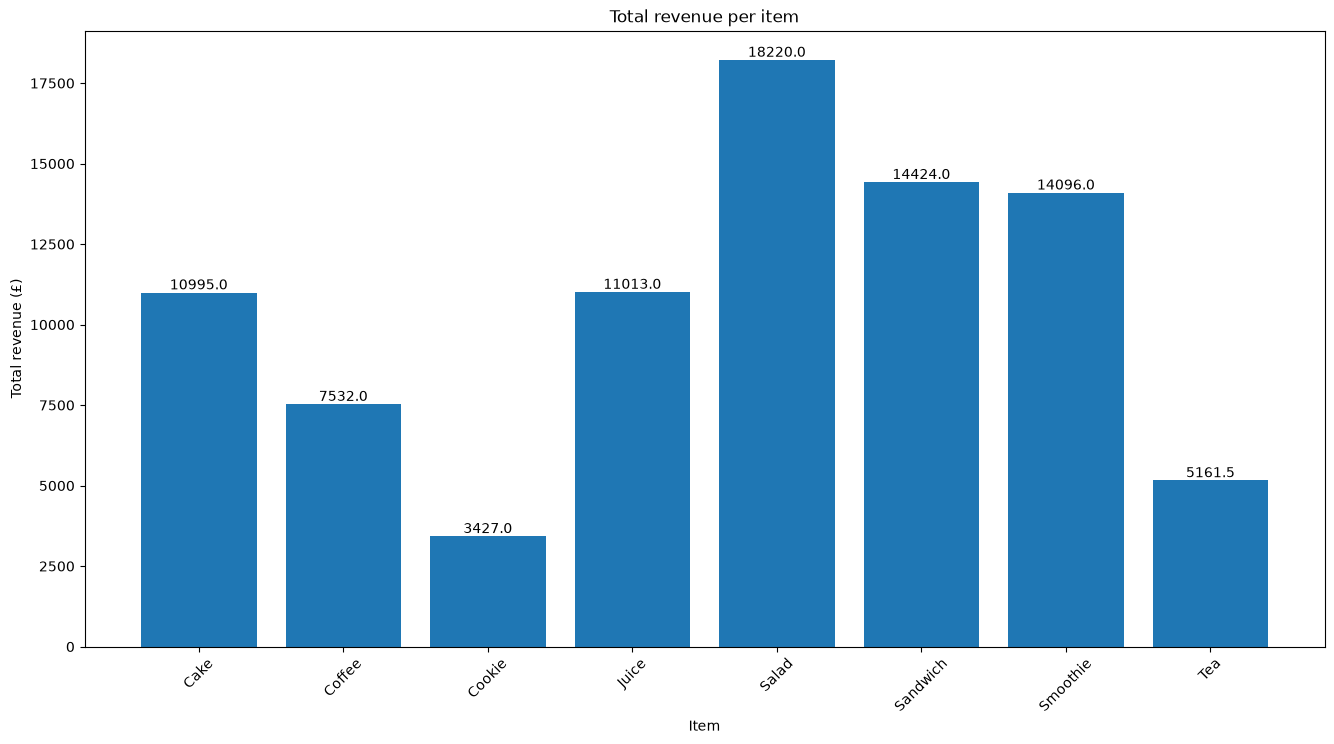

In [41]:
#Graphing the total revenue per item using a bar chart

plt.figure(figsize=(16,8))

plt.bar(total_revenue_per_item.index, total_revenue_per_item.values)
plt.title("Total revenue per item")
plt.xlabel("Item")
plt.ylabel("Total revenue (£)")


#adding value lables above each bar
for item,amount in enumerate(total_revenue_per_item):
    plt.text(item, amount+100, amount , ha='center')

plt.xticks(rotation=45)
plt.show()